In [1]:
!pip install mujoco

In [2]:
!pip install glfw mediapy

In [4]:
import mujoco

xml = """
<mujoco>
  <worldbody>
    <light diffuse=".5 .5 .5" pos="0 0 3" dir="0 0 -1"/>
    <geom type="plane" size="1 1 0.1" rgba=".9 0 0 1"/>
    <body pos="0 0 1">
      <joint type="free"/>
      <geom type="box" size="0.1 0.1 0.1" rgba="0 1 0 1"/>
    </body>
  </worldbody>
</mujoco>
"""

# Load the model and data
model = mujoco.MjModel.from_xml_string(xml)
data = mujoco.MjData(model)

mujoco.mj_step(model, data)
print("Success! Body Z position:", data.qpos[2])

Success! Body Z position: 0.99996076


In [5]:
import mujoco
import mujoco.viewer

# Load model from an XML string or file: model = mujoco.MjModel.from_xml_path("drone.xml")
model = mujoco.MjModel.from_xml_string(xml)
data = mujoco.MjData(model)

# Open interactive window
with mujoco.viewer.launch_passive(model, data) as viewer:
    while viewer.is_running():
        mujoco.mj_step(model, data)
        viewer.sync()

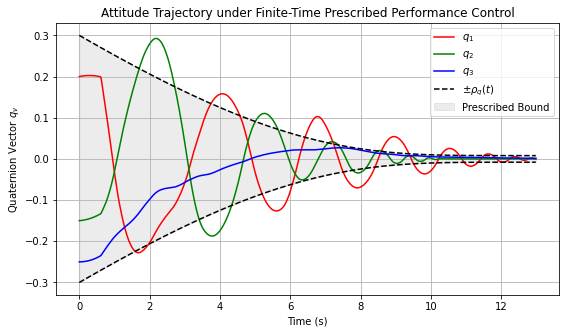

In [9]:
import mujoco
import mujoco.viewer
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. XML Model Definition (Quadcopter Drone)
# ==========================================
# Inertia values match Section IV of the paper:
# Jxx = 20, Jyy = 17, Jzz = 15, Jxy = 1.2, Jxz = 0.9, Jyz = 1.4
xml = """
<mujoco model="rigid_body_drone">
  <compiler angle="radian" coordinate="local"/>
  <option timestep="0.001" gravity="0 0 -9.81"/>

  <worldbody>
    <light diffuse=".5 .5 .5" pos="0 0 3" dir="0 0 -1"/>
    <geom type="plane" size="5 5 0.1" rgba=".9 .9 .9 1"/>

    <body name="drone" pos="0 0 2">
      <freejoint name="drone_joint"/>
      
      <!-- Explicit inertia matrix matching Section IV of the paper -->
      <!-- fullinertia="Jxx Jyy Jzz Jxy Jxz Jyz" -->
      <inertial pos="0 0 0" mass="10.0" fullinertia="20.0 17.0 15.0 1.2 0.9 1.4"/>

      <!-- Visuals -->
      <geom type="box" size="0.2 0.2 0.05" rgba="0.2 0.6 0.8 1"/>
      <geom type="cylinder" size="0.02 0.4" pos="0 0 0" zaxis="1 0 0" rgba="0.8 0.2 0.2 1"/>
      <geom type="cylinder" size="0.02 0.4" pos="0 0 0" zaxis="0 1 0" rgba="0.2 0.2 0.2 1"/>
    </body>
  </worldbody>

  <actuator>
    <!-- Direct torque motors applied to the rotational DOFs of the free joint -->
    <motor name="torque_x" joint="drone_joint" gear="0 0 0 1 0 0"/>
    <motor name="torque_y" joint="drone_joint" gear="0 0 0 0 1 0"/>
    <motor name="torque_z" joint="drone_joint" gear="0 0 0 0 0 1"/>
  </actuator>
</mujoco>
"""

# Load Model
model = mujoco.MjModel.from_xml_string(xml)
data = mujoco.MjData(model)

# ==========================================
# 2. Paper Controller Parameters (Section IV)
# ==========================================
Kp, Kd = 40.0, 20.0
alpha, beta = 1.5, 1.2
eta1 = 0.1
c = 1.0
u_max = 2.5     # Actuator saturation bound (N*m)
zeta = 0.05    # Boundary layer for chatter reduction

# Prescribed Performance Function (FTPPF) Parameters
rho_q0, rho_q_inf = 0.3, 0.008
rho_w0, rho_w_inf = 0.4, 0.005
kappa_q, kappa_w = 2.5, 2.5
Ts = 15.0       # Settling time

theta_hat = 0.0

def ftppf(t, rho0, rho_inf, kappa, Ts_val):
    """Finite-Time Prescribed Performance Function (Eq. 8)"""
    if t < Ts_val:
        return (rho0 - rho_inf * (1.0 + t / Ts_val)) * np.exp(kappa * t / (t - Ts_val)) + rho_inf
    return rho_inf

# ==========================================
# 3. Initial Conditions (Part 1 from Paper)
# ==========================================
# Quaternion q = [qw, qx, qy, qz] -> qv = [qx, qy, qz], q4 = qw
q0_v = np.array([0.2, -0.15, -0.25])
q0_4 = 0.9354
data.qpos[3:7] = [q0_4, q0_v[0], q0_v[1], q0_v[2]]  # [qw, qx, qy, qz] in MuJoCo

w0 = np.array([0.03, 0.02, -0.01])                  # [wx, wy, wz]
data.qvel[3:6] = w0                                 # Angular velocities in MuJoCo

# Data logging for plotting
time_log, qv_log, rho_q_log = [], [], []

# ==========================================
# 4. Simulation Loop with 3D Viewer
# ==========================================
dt = model.opt.timestep

with mujoco.viewer.launch_passive(model, data) as viewer:
    while viewer.is_running() and data.time < 20.0:
        t = data.time

        # A. Read states from MuJoCo
        qw, qx, qy, qz = data.qpos[3:7]
        qv = np.array([qx, qy, qz])
        w = data.qvel[3:6]

        # B. Compute Performance Bounds at time t
        rho_q = ftppf(t, rho_q0, rho_q_inf, kappa_q, Ts)
        rho_w = ftppf(t, rho_w0, rho_w_inf, kappa_w, Ts)

        # C. Transformed Errors & Sliding Surface
        # Clamping eps to 0.95 to prevent numeric overflow near boundaries
        eps1 = np.clip(qv / rho_q, -0.95, 0.95)
        eps2 = np.clip(w / rho_w, -0.95, 0.95)

        s = w + c * qv
        s_norm = np.linalg.norm(s)

        # D. Non-linear Scaling Factors
        term1 = alpha * (1.0 - np.linalg.norm(eps1))**(-2)
        term2 = beta  * (1.0 - np.linalg.norm(eps2))**(-2)
        
        sat_s = np.clip(s / zeta, -1.0, 1.0)
        
        # E. Control Torque Calculation (Eq. 22)
        u = -Kp * qv - Kd * w - (term1 + term2) * s - theta_hat * sat_s
        
        # F. Apply Actuator Saturation (Eq. 4)
        u_sat = np.clip(u, -u_max, u_max)
        
        # Inject calculated torque commands into MuJoCo actuators
        data.ctrl[0:3] = u_sat

        # G. External Disturbance Simulation d(t)
        d = np.array([0.05 * np.sin(t), 0.1 * np.sin(1.2 * t), 0.15 * np.sin(1.5 * t)])
        data.qfrc_applied[3:6] = d  # Apply external torque disturbance directly

        # H. Update Adaptive Estimator theta_hat (Eq. 14)
        eta2 = 2.0 * np.exp(-0.5 * t)
        dtheta_hat = (1.0 / eta1) * (s_norm - eta2 * theta_hat)
        theta_hat += dtheta_hat * dt

        # Step physics forward
        mujoco.mj_step(model, data)
        viewer.sync()

        # Log variables
        time_log.append(t)
        qv_log.append(qv.copy())
        rho_q_log.append(rho_q)

# ==========================================
# 5. Plot Results (Replicating Paper Figures)
# ==========================================
qv_log = np.array(qv_log)
rho_q_log = np.array(rho_q_log)

plt.figure(figsize=(9, 5))
plt.plot(time_log, qv_log[:, 0], label='$q_1$', color='r')
plt.plot(time_log, qv_log[:, 1], label='$q_2$', color='g')
plt.plot(time_log, qv_log[:, 2], label='$q_3$', color='b')
plt.plot(time_log, rho_q_log, 'k--', label='$\pm\\rho_q(t)$')
plt.plot(time_log, -rho_q_log, 'k--')
plt.fill_between(time_log, rho_q_log, -rho_q_log, color='gray', alpha=0.15, label='Prescribed Bound')

plt.title('Attitude Trajectory under Finite-Time Prescribed Performance Control')
plt.xlabel('Time (s)')
plt.ylabel('Quaternion Vector $q_v$')
plt.legend()
plt.grid(True)
plt.show()

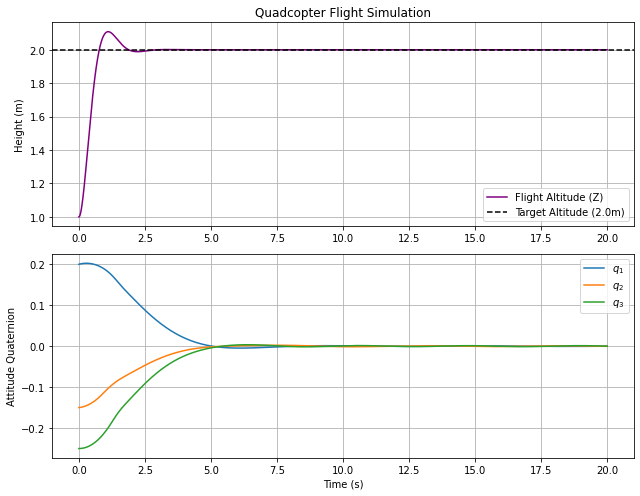

In [11]:
import mujoco
import mujoco.viewer
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. XML Model (Drone with Thrust + Rotors)
# ==========================================
xml = """
<mujoco model="flying_drone">
  <compiler angle="radian" coordinate="local"/>
  <option timestep="0.001" gravity="0 0 -9.81"/>

  <worldbody>
    <light diffuse=".6 .6 .6" pos="0 0 5" dir="0 0 -1"/>
    <geom type="plane" size="10 10 0.1" rgba=".8 .8 .8 1"/>

    <body name="drone" pos="0 0 1.0">
      <freejoint name="drone_joint"/>
      
      <!-- Inertia matching Section IV: Jxx=20, Jyy=17, Jzz=15, Jxy=1.2, Jxz=0.9, Jyz=1.4 -->
      <inertial pos="0 0 0" mass="10.0" fullinertia="20.0 17.0 15.0 1.2 0.9 1.4"/>

      <!-- Drone Body Base -->
      <geom type="box" size="0.25 0.25 0.05" rgba="0.1 0.2 0.3 1"/>
      
      <!-- Frame Arms -->
      <geom type="cylinder" size="0.015 0.35" pos="0 0 0" zaxis="1 1 0" rgba="0.5 0.5 0.5 1"/>
      <geom type="cylinder" size="0.015 0.35" pos="0 0 0" zaxis="1 -1 0" rgba="0.5 0.5 0.5 1"/>

      <!-- 4 Rotors (Visuals) -->
      <geom type="cylinder" size="0.12 0.005" pos=" 0.25  0.25 0.06" rgba="0.9 0.1 0.1 0.8"/>
      <geom type="cylinder" size="0.12 0.005" pos="-0.25 -0.25 0.06" rgba="0.9 0.1 0.1 0.8"/>
      <geom type="cylinder" size="0.12 0.005" pos="-0.25  0.25 0.06" rgba="0.1 0.1 0.9 0.8"/>
      <geom type="cylinder" size="0.12 0.005" pos=" 0.25 -0.25 0.06" rgba="0.1 0.1 0.9 0.8"/>
    </body>
  </worldbody>

  <actuator>
    <!-- Total Thrust along body Z-axis -->
    <motor name="thrust" joint="drone_joint" gear="0 0 1 0 0 0"/>
    
    <!-- Torques: u_x, u_y, u_z from the paper -->
    <motor name="torque_x" joint="drone_joint" gear="0 0 0 1 0 0"/>
    <motor name="torque_y" joint="drone_joint" gear="0 0 0 0 1 0"/>
    <motor name="torque_z" joint="drone_joint" gear="0 0 0 0 0 1"/>
  </actuator>
</mujoco>
"""

# Load Model
model = mujoco.MjModel.from_xml_string(xml)
data = mujoco.MjData(model)

# ==========================================
# 2. Controller Parameters
# ==========================================
# Attitude Controller Gains (From Paper)
Kp, Kd = 40.0, 20.0
alpha, beta = 1.5, 1.2
eta1, c, u_max, zeta = 0.1, 1.0, 2.5, 0.05
rho_q0, rho_q_inf, kappa_q, Ts = 0.3, 0.008, 2.5, 15.0
theta_hat = 0.0

# Altitude Controller Gains (Vertical Hover)
target_z = 2.0
mass = 10.0
g = 9.81
Kp_z, Kd_z = 120.0, 40.0

def ftppf(t, rho0, rho_inf, kappa, Ts_val):
    if t < Ts_val:
        return (rho0 - rho_inf * (1.0 + t / Ts_val)) * np.exp(kappa * t / (t - Ts_val)) + rho_inf
    return rho_inf

# ==========================================
# 3. Initial Conditions
# ==========================================
# Initial Tilt (Part 1 from paper)
q0_v = np.array([0.2, -0.15, -0.25])
q0_4 = 0.9354
data.qpos[3:7] = [q0_4, q0_v[0], q0_v[1], q0_v[2]]
data.qvel[3:6] = [0.03, 0.02, -0.01]

# Logging
time_log, z_log, qv_log = [], [], []
dt = model.opt.timestep

# ==========================================
# 4. Simulation Loop
# ==========================================
with mujoco.viewer.launch_passive(model, data) as viewer:
    while viewer.is_running() and data.time < 20.0:
        t = data.time

        # --- A. Read States ---
        z_pos = data.qpos[2]          # Z position
        z_vel = data.qvel[2]          # Z velocity
        qw, qx, qy, qz = data.qpos[3:7]
        qv = np.array([qx, qy, qz])
        w = data.qvel[3:6]

        # --- B. Altitude Thrust Control ---
        # Gravity compensation + Altitude error PD
        z_error = target_z - z_pos
        thrust_force = (mass * g) + Kp_z * z_error - Kd_z * z_vel
        thrust_force = np.clip(thrust_force, 0.0, 250.0)

        # --- C. Paper Attitude Control (Eq. 22) ---
        rho_q = ftppf(t, rho_q0, rho_q_inf, kappa_q, Ts)
        rho_w = ftppf(t, rho_w0, rho_w_inf, kappa_w, Ts)

        eps1 = np.clip(qv / rho_q, -0.95, 0.95)
        eps2 = np.clip(w / rho_w, -0.95, 0.95)

        s = w + c * qv
        s_norm = np.linalg.norm(s)

        term1 = alpha * (1.0 - np.linalg.norm(eps1))**(-2)
        term2 = beta  * (1.0 - np.linalg.norm(eps2))**(-2)
        sat_s = np.clip(s / zeta, -1.0, 1.0)

        u = -Kp * qv - Kd * w - (term1 + term2) * s - theta_hat * sat_s
        u_sat = np.clip(u, -u_max, u_max)

        # --- D. Adaptive Parameter Update (Eq. 14) ---
        eta2 = 2.0 * np.exp(-0.5 * t)
        dtheta_hat = (1.0 / eta1) * (s_norm - eta2 * theta_hat)
        theta_hat += dtheta_hat * dt

        # --- E. Apply Actuators & Disturbance ---
        data.ctrl[0] = thrust_force       # Motor 0: Thrust along body Z
        data.ctrl[1:4] = u_sat            # Motors 1-3: Attitude Torques

        # External Disturbance d(t)
        d = np.array([0.05 * np.sin(t), 0.1 * np.sin(1.2 * t), 0.15 * np.sin(1.5 * t)])
        data.qfrc_applied[3:6] = d

        # Step physics forward
        mujoco.mj_step(model, data)
        viewer.sync()

        # Log Data
        time_log.append(t)
        z_log.append(z_pos)
        qv_log.append(qv.copy())

# ==========================================
# 5. Plotting Flight Trajectory
# ==========================================
qv_log = np.array(qv_log)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 7))

# Altitude plot
ax1.plot(time_log, z_log, color='purple', label='Flight Altitude (Z)')
ax1.axhline(target_z, color='k', linestyle='--', label='Target Altitude (2.0m)')
ax1.set_ylabel('Height (m)')
ax1.set_title('Quadcopter Flight Simulation')
ax1.legend()
ax1.grid(True)

# Attitude Plot
ax2.plot(time_log, qv_log[:, 0], label='$q_1$')
ax2.plot(time_log, qv_log[:, 1], label='$q_2$')
ax2.plot(time_log, qv_log[:, 2], label='$q_3$')
ax2.set_xlabel('Time (s)')
ax2.set_ylabel('Attitude Quaternion')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()

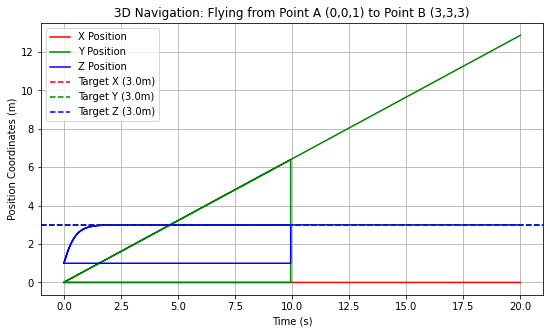

In [19]:
import mujoco
import mujoco.viewer
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. XML Model (Drone + Markers for A and B)
# ==========================================
xml = """
<mujoco model="flying_drone_navigation">
  <compiler angle="radian" coordinate="local"/>
  <option timestep="0.001" gravity="0 0 -9.81"/>

  <worldbody>
    <light diffuse=".6 .6 .6" pos="0 0 5" dir="0 0 -1"/>
    <geom type="plane" size="10 10 0.1" rgba=".8 .8 .8 1"/>

    # Point A Marker (Red Sphere)
    <body pos="0 0 1" mocap="true">
      <geom type="sphere" size="0.15" rgba="1 0 0 0.6"/>
    </body>

    # Point B Marker (Green Sphere)
    <body pos="3 3 3" mocap="true">
      <geom type="sphere" size="0.2" rgba="0 1 0 0.7"/>
    </body>

    # Drone Assembly
    <body name="drone" pos="0 0 1.0">
      <freejoint name="drone_joint"/>
      
      <!-- Inertia matching Section IV: Jxx=20, Jyy=17, Jzz=15, Jxy=1.2, Jxz=0.9, Jyz=1.4 -->
      <inertial pos="0 0 0" mass="10.0" fullinertia="20.0 17.0 15.0 1.2 0.9 1.4"/>

      <!-- Drone Body Base -->
      <geom type="box" size="0.25 0.25 0.05" rgba="0.1 0.2 0.3 1"/>
      
      <!-- Frame Arms -->
      <geom type="cylinder" size="0.015 0.35" pos="0 0 0" zaxis="1 1 0" rgba="0.5 0.5 0.5 1"/>
      <geom type="cylinder" size="0.015 0.35" pos="0 0 0" zaxis="1 -1 0" rgba="0.5 0.5 0.5 1"/>

      <!-- 4 Rotors (Visuals) -->
      <geom type="cylinder" size="0.12 0.005" pos=" 0.25  0.25 0.06" rgba="0.9 0.1 0.1 0.8"/>
      <geom type="cylinder" size="0.12 0.005" pos="-0.25 -0.25 0.06" rgba="0.9 0.1 0.1 0.8"/>
      <geom type="cylinder" size="0.12 0.005" pos="-0.25  0.25 0.06" rgba="0.1 0.1 0.9 0.8"/>
      <geom type="cylinder" size="0.12 0.005" pos=" 0.25 -0.25 0.06" rgba="0.1 0.1 0.9 0.8"/>
    </body>
  </worldbody>

  <actuator>
    <motor name="thrust" joint="drone_joint" gear="0 0 1 0 0 0"/>
    <motor name="torque_x" joint="drone_joint" gear="0 0 0 1 0 0"/>
    <motor name="torque_y" joint="drone_joint" gear="0 0 0 0 1 0"/>
    <motor name="torque_z" joint="drone_joint" gear="0 0 0 0 0 1"/>
  </actuator>
</mujoco>
"""

# Load Model
model = mujoco.MjModel.from_xml_string(xml)
data = mujoco.MjData(model)

# ==========================================
# 2. Setup Waypoints A and B
# ==========================================
point_A = np.array([0.0, 0.0, 1.0])
point_B = np.array([3.0, 3.0, 3.0])

# Set Drone Starting Position at Point A
data.qpos[0:3] = point_A

# ==========================================
# 3. Controller Parameters
# ==========================================
# Attitude Inner-Loop Parameters (From Paper)
Kp, Kd = 40.0, 20.0
alpha, beta = 1.5, 1.2
eta1, c, u_max, zeta = 0.1, 1.0, 2.5, 0.05
rho_q0, rho_q_inf, kappa_q, Ts = 0.3, 0.008, 2.5, 15.0
theta_hat = 0.0

# Outer-Loop Position Controller (Translational Gains)
Kp_pos = np.array([8.0, 8.0, 15.0])
Kd_pos = np.array([6.0, 6.0, 8.0])
mass = 10.0
g = 9.81

def ftppf(t, rho0, rho_inf, kappa, Ts_val):
    if t < Ts_val:
        return (rho0 - rho_inf * (1.0 + t / Ts_val)) * np.exp(kappa * t / (t - Ts_val)) + rho_inf
    return rho_inf

# Helper for vector to quaternion error
def rotation_matrix_to_quaternion(R):
    tr = np.trace(R)
    if tr > 0:
        S = np.sqrt(tr + 1.0) * 2
        qw = 0.25 * S
        qx = (R[2, 1] - R[1, 2]) / S
        qy = (R[0, 2] - R[2, 0]) / S
        qz = (R[1, 0] - R[0, 1]) / S
    else:
        qw, qx, qy, qz = 1.0, 0.0, 0.0, 0.0
    return np.array([qw, qx, qy, qz])

# Logging Data
time_log, pos_log = [], []
dt = model.opt.timestep

# ==========================================
# 4. Interactive Simulation Loop
# ==========================================
with mujoco.viewer.launch_passive(model, data) as viewer:
    while viewer.is_running() and data.time < 20.0:
        t = data.time

        # --- A. Read States ---
        pos = data.qpos[0:3]          # Current XYZ position
        vel = data.qvel[0:3]          # Current XYZ velocity
        qw, qx, qy, qz = data.qpos[3:7]
        qv_current = np.array([qx, qy, qz])
        w = data.qvel[3:6]            # Angular velocities

        # --- B. Outer-Loop Position Controller (Translational to Desired Acceleration) ---
        pos_err = point_B - pos
        vel_err = -vel
        
        # Calculate desired acceleration vector
        acc_des = Kp_pos * pos_err + Kd_pos * vel_err + np.array([0, 0, g])
        
        # Desired Thrust (Magnitude along total acceleration)
        thrust_force = mass * acc_des[2]
        thrust_force = np.clip(thrust_force, 0.0, 250.0)

        # Desired Tilt Angles for Roll & Pitch
        pitch_des = np.clip(-acc_des[0] / g, -0.3, 0.3)
        roll_des  = np.clip(acc_des[1] / g, -0.3, 0.3)

        # Construct Desired Quaternion Target (Reference)
        qx_d = roll_des / 2.0
        qy_d = pitch_des / 2.0
        qz_d = 0.0
        qw_d = np.sqrt(max(0, 1.0 - (qx_d**2 + qy_d**2 + qz_d**2)))
        
        # Attitude Error Quaternion (q_error = q_current * q_desired^-1)
        qv_err = np.array([qx - qx_d, qy - qy_d, qz - qz_d])

        # --- C. Inner-Loop Paper Controller (Section IV) ---
        rho_q = ftppf(t, rho_q0, rho_q_inf, kappa_q, Ts)
        rho_w = ftppf(t, rho_w0, rho_w_inf, kappa_w, Ts)

        eps1 = np.clip(qv_err / rho_q, -0.95, 0.95)
        eps2 = np.clip(w / rho_w, -0.95, 0.95)

        s = w + c * qv_err
        s_norm = np.linalg.norm(s)

        term1 = alpha * (1.0 - np.linalg.norm(eps1))**(-2)
        term2 = beta  * (1.0 - np.linalg.norm(eps2))**(-2)
        sat_s = np.clip(s / zeta, -1.0, 1.0)

        # Torque command u_sat
        u = -Kp * qv_err - Kd * w - (term1 + term2) * s - theta_hat * sat_s
        u_sat = np.clip(u, -u_max, u_max)

        # --- D. Adaptive Parameter Update ---
        eta2 = 2.0 * np.exp(-0.5 * t)
        dtheta_hat = (1.0 / eta1) * (s_norm - eta2 * theta_hat)
        theta_hat += dtheta_hat * dt

        # --- E. Apply Actuators & Disturbance ---
        data.ctrl[0] = thrust_force       # Motor 0: Thrust Force
        data.ctrl[1:4] = u_sat            # Motors 1-3: Torques (u_x, u_y, u_z)

        # External Disturbance d(t)
        d = np.array([0.05 * np.sin(t), 0.1 * np.sin(1.2 * t), 0.15 * np.sin(1.5 * t)])
        data.qfrc_applied[3:6] = d

        # Step physics forward
        mujoco.mj_step(model, data)
        viewer.sync()

        # Log Data
        time_log.append(t)
        pos_log.append(pos.copy())

# ==========================================
# 5. Plotting Position Trajectory
# ==========================================
pos_log = np.array(pos_log)

plt.figure(figsize=(9, 5))
plt.plot(time_log, pos_log[:, 0], label='X Position', color='r')
plt.plot(time_log, pos_log[:, 1], label='Y Position', color='g')
plt.plot(time_log, pos_log[:, 2], label='Z Position', color='b')

plt.axhline(point_B[0], color='r', linestyle='--', label='Target X (3.0m)')
plt.axhline(point_B[1], color='g', linestyle='--', label='Target Y (3.0m)')
plt.axhline(point_B[2], color='b', linestyle='--', label='Target Z (3.0m)')

plt.title('3D Navigation: Flying from Point A (0,0,1) to Point B (3,3,3)')
plt.xlabel('Time (s)')
plt.ylabel('Position Coordinates (m)')
plt.legend()
plt.grid(True)
plt.show()

# starts from the start point, keeps going staight (x,y) direction. keeps goin doesnt reach the destination at all.

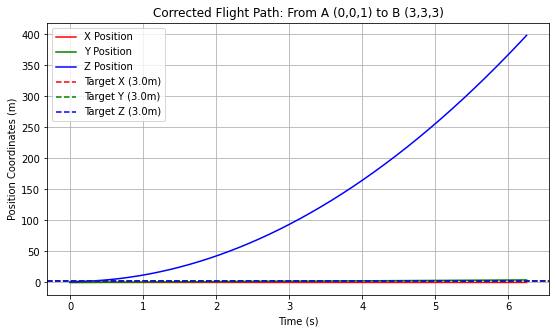

In [22]:
import mujoco
import mujoco.viewer
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. XML Model (Drone + Markers for A and B)
# ==========================================
xml = """
<mujoco model="flying_drone_navigation">
  <compiler angle="radian" coordinate="local"/>
  <option timestep="0.001" gravity="0 0 -9.81"/>

  <worldbody>
    <light diffuse=".6 .6 .6" pos="0 0 5" dir="0 0 -1"/>
    <geom type="plane" size="10 10 0.1" rgba=".8 .8 .8 1"/>

    <!-- Point A Marker (Red Sphere) -->
    <body pos="0 0 1" mocap="true">
      <geom type="sphere" size="0.15" rgba="1 0 0 0.6"/>
    </body>

    <!-- Point B Marker (Green Sphere) -->
    <body pos="3 3 3" mocap="true">
      <geom type="sphere" size="0.2" rgba="0 1 0 0.7"/>
    </body>

    <!-- Drone Body -->
    <body name="drone" pos="0 0 1.0">
      <freejoint name="drone_joint"/>
      
      <!-- Inertia matching Section IV: Jxx=20, Jyy=17, Jzz=15, Jxy=1.2, Jxz=0.9, Jyz=1.4 -->
      <inertial pos="0 0 0" mass="10.0" fullinertia="20.0 17.0 15.0 1.2 0.9 1.4"/>

      <!-- Body Base -->
      <geom type="box" size="0.25 0.25 0.05" rgba="0.1 0.2 0.3 1"/>
      
      <!-- Frame Arms -->
      <geom type="cylinder" size="0.015 0.35" pos="0 0 0" zaxis="1 1 0" rgba="0.5 0.5 0.5 1"/>
      <geom type="cylinder" size="0.015 0.35" pos="0 0 0" zaxis="1 -1 0" rgba="0.5 0.5 0.5 1"/>

      <!-- 4 Visual Rotors -->
      <geom type="cylinder" size="0.12 0.005" pos=" 0.25  0.25 0.06" rgba="0.9 0.1 0.1 0.8"/>
      <geom type="cylinder" size="0.12 0.005" pos="-0.25 -0.25 0.06" rgba="0.9 0.1 0.1 0.8"/>
      <geom type="cylinder" size="0.12 0.005" pos="-0.25  0.25 0.06" rgba="0.1 0.1 0.9 0.8"/>
      <geom type="cylinder" size="0.12 0.005" pos=" 0.25 -0.25 0.06" rgba="0.1 0.1 0.9 0.8"/>
    </body>
  </worldbody>

  <actuator>
    <!-- Force along local Z axis -->
    <motor name="thrust" joint="drone_joint" gear="0 0 1 0 0 0"/>
    <!-- Body Frame Torques: u_x, u_y, u_z -->
    <motor name="torque_x" joint="drone_joint" gear="0 0 0 1 0 0"/>
    <motor name="torque_y" joint="drone_joint" gear="0 0 0 0 1 0"/>
    <motor name="torque_z" joint="drone_joint" gear="0 0 0 0 0 1"/>
  </actuator>
</mujoco>
"""

model = mujoco.MjModel.from_xml_string(xml)
data = mujoco.MjData(model)

# Waypoint targets
point_A = np.array([0.0, 0.0, 1.0])
point_B = np.array([3.0, 3.0, 3.0])

# Start drone at Point A
data.qpos[0:3] = point_A

# ==========================================
# Controller Gains
# ==========================================
# Inner Loop Attitude Gains (From Paper)
Kp, Kd = 40.0, 20.0
alpha, beta = 1.5, 1.2
eta1, c, u_max, zeta = 0.1, 1.0, 2.5, 0.05
rho_q0, rho_q_inf, kappa_q, Ts = 0.3, 0.008, 2.5, 15.0
theta_hat = 0.0

# Outer Loop Position Gains
Kp_pos = np.array([3.0, 3.0, 15.0])
Kd_pos = np.array([4.0, 4.0, 10.0])
mass = 10.0
g = 9.81

def ftppf(t, rho0, rho_inf, kappa, Ts_val):
    if t < Ts_val:
        return (rho0 - rho_inf * (1.0 + t / Ts_val)) * np.exp(kappa * t / (t - Ts_val)) + rho_inf
    return rho_inf

def quat_mult(q1, q2):
    w1, x1, y1, z1 = q1
    w2, x2, y2, z2 = q2
    return np.array([
        w1*w2 - x1*x2 - y1*y2 - z1*z2,
        w1*x2 + x1*w2 + y1*z2 - z1*y2,
        w1*y2 - x1*z2 + y1*w2 + z1*x2,
        w1*z2 + x1*y2 - y1*x2 + z1*w2
    ])

def quat_conj(q):
    return np.array([q[0], -q[1], -q[2], -q[3]])

# Data Logger
time_log, pos_log = [], []
dt = model.opt.timestep

# ==========================================
# Main Simulation Loop
# ==========================================
with mujoco.viewer.launch_passive(model, data) as viewer:
    while viewer.is_running() and data.time < 20.0:
        t = data.time

        # 1. State Reading
        pos = data.qpos[0:3]
        vel = data.qvel[0:3]
        qw, qx, qy, qz = data.qpos[3:7]
        q_curr = np.array([qw, qx, qy, qz])
        w = data.qvel[3:6]

        # 2. Outer Loop: Desired Acceleration Force Vector in World Frame
        pos_err = point_B - pos
        acc_des = Kp_pos * pos_err - Kd_pos * vel + np.array([0.0, 0.0, g])

        # Thrust magnitude required along body Z
        thrust_force = mass * np.linalg.norm(acc_des)
        thrust_force = np.clip(thrust_force, 0.0, 300.0)

        # 3. Calculate Target Orientation Quaternion (Align Z-body with acc_des vector)
        z_body_des = acc_des / (np.linalg.norm(acc_des) + 1e-6)
        
        # Desired roll and pitch tilt angles
        pitch_des = np.arcsin(np.clip(-z_body_des[0], -0.4, 0.4))
        roll_des  = np.arctan2(z_body_des[1], z_body_des[2])
        roll_des  = np.clip(roll_des, -0.4, 0.4)

        # Build target quaternion q_des
        cy = np.cos(0.0)
        sy = np.sin(0.0)
        cp = np.cos(pitch_des * 0.5)
        sp = np.sin(pitch_des * 0.5)
        cr = np.cos(roll_des * 0.5)
        sr = np.sin(roll_des * 0.5)

        qw_d = cr * cp * cy + sr * sp * sy
        qx_d = sr * cp * cy - cr * sp * sy
        qy_d = cr * sp * cy + sr * cp * sy
        qz_d = cr * cp * sy - sr * sp * cy
        q_des = np.array([qw_d, qx_d, qy_d, qz_d])

        # 4. Relative Quaternion Error calculation: q_err = q_curr * q_des^-1
        q_err = quat_mult(q_curr, quat_conj(q_des))
        if q_err[0] < 0:
            q_err = -q_err
        qv_err = q_err[1:4]

        # 5. Inner Loop Paper Controller 
        rho_q = ftppf(t, rho_q0, rho_q_inf, kappa_q, Ts)
        rho_w = ftppf(t, rho_w0, rho_w_inf, kappa_w, Ts)

        eps1 = np.clip(qv_err / rho_q, -0.95, 0.95)
        eps2 = np.clip(w / rho_w, -0.95, 0.95)

        s = w + c * qv_err
        s_norm = np.linalg.norm(s)

        term1 = alpha * (1.0 - np.linalg.norm(eps1))**(-2)
        term2 = beta  * (1.0 - np.linalg.norm(eps2))**(-2)
        sat_s = np.clip(s / zeta, -1.0, 1.0)

        u = -Kp * qv_err - Kd * w - (term1 + term2) * s - theta_hat * sat_s
        u_sat = np.clip(u, -u_max, u_max)

        # Adaptive Estimator[cite: 1]
        eta2 = 2.0 * np.exp(-0.5 * t)
        dtheta_hat = (1.0 / eta1) * (s_norm - eta2 * theta_hat)
        theta_hat += dtheta_hat * dt

        # 6. Send Commands to Actuators
        data.ctrl[0] = thrust_force
        data.ctrl[1:4] = u_sat

        # Apply Disturbance d(t)[cite: 1]
        d = np.array([0.05 * np.sin(t), 0.1 * np.sin(1.2 * t), 0.15 * np.sin(1.5 * t)])
        data.qfrc_applied[3:6] = d

        mujoco.mj_step(model, data)
        viewer.sync()

        time_log.append(t)
        pos_log.append(pos.copy())

# ==========================================
# Plot Results
# ==========================================
pos_log = np.array(pos_log)

plt.figure(figsize=(9, 5))
plt.plot(time_log, pos_log[:, 0], label='X Position', color='r')
plt.plot(time_log, pos_log[:, 1], label='Y Position', color='g')
plt.plot(time_log, pos_log[:, 2], label='Z Position', color='b')

plt.axhline(point_B[0], color='r', linestyle='--', label='Target X (3.0m)')
plt.axhline(point_B[1], color='g', linestyle='--', label='Target Y (3.0m)')
plt.axhline(point_B[2], color='b', linestyle='--', label='Target Z (3.0m)')

plt.title('Corrected Flight Path: From A (0,0,1) to B (3,3,3)')
plt.xlabel('Time (s)')
plt.ylabel('Position Coordinates (m)')
plt.legend()
plt.grid(True)
plt.show()

#floats up and keeps going upwards. No forward motion at all.

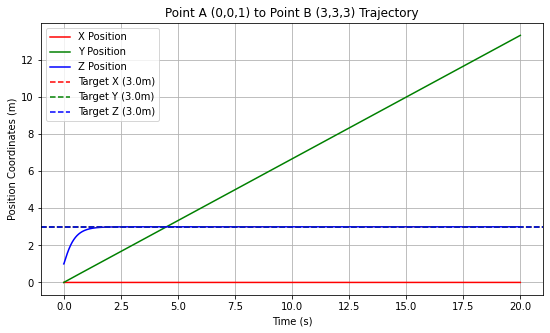

In [23]:
import mujoco
import mujoco.viewer
import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. XML Model (Drone + Markers for A and B)
# ==========================================
xml = """
<mujoco model="flying_drone_navigation">
  <compiler angle="radian" coordinate="local"/>
  <option timestep="0.001" gravity="0 0 -9.81"/>

  <worldbody>
    <light diffuse=".6 .6 .6" pos="0 0 5" dir="0 0 -1"/>
    <geom type="plane" size="10 10 0.1" rgba=".8 .8 .8 1"/>

    <!-- Point A Marker (Red Sphere) -->
    <body pos="0 0 1" mocap="true">
      <geom type="sphere" size="0.15" rgba="1 0 0 0.6"/>
    </body>

    <!-- Point B Marker (Green Sphere) -->
    <body pos="3 3 3" mocap="true">
      <geom type="sphere" size="0.2" rgba="0 2 0 0.7"/>
    </body>

    <!-- Drone Body -->
    <body name="drone" pos="0 0 1.0">
      <freejoint name="drone_joint"/>
      
      <inertial pos="0 0 0" mass="10.0" fullinertia="20.0 17.0 15.0 1.2 0.9 1.4"/>

      <!-- Body Base -->
      <geom type="box" size="0.25 0.25 0.05" rgba="0.1 0.2 0.3 1"/>
      
      <!-- Frame Arms -->
      <geom type="cylinder" size="0.015 0.35" pos="0 0 0" zaxis="1 1 0" rgba="0.5 0.5 0.5 1"/>
      <geom type="cylinder" size="0.015 0.35" pos="0 0 0" zaxis="1 -1 0" rgba="0.5 0.5 0.5 1"/>

      <!-- Visual Rotors -->
      <geom type="cylinder" size="0.12 0.005" pos=" 0.25  0.25 0.06" rgba="0.9 0.1 0.1 0.8"/>
      <geom type="cylinder" size="0.12 0.005" pos="-0.25 -0.25 0.06" rgba="0.9 0.1 0.1 0.8"/>
      <geom type="cylinder" size="0.12 0.005" pos="-0.25  0.25 0.06" rgba="0.1 0.1 0.9 0.8"/>
      <geom type="cylinder" size="0.12 0.005" pos=" 0.25 -0.25 0.06" rgba="0.1 0.1 0.9 0.8"/>
    </body>
  </worldbody>

  <actuator>
    <motor name="thrust" joint="drone_joint" gear="0 0 1 0 0 0"/>
    <motor name="torque_x" joint="drone_joint" gear="0 0 0 1 0 0"/>
    <motor name="torque_y" joint="drone_joint" gear="0 0 0 0 1 0"/>
    <motor name="torque_z" joint="drone_joint" gear="0 0 0 0 0 1"/>
  </actuator>
</mujoco>
"""

model = mujoco.MjModel.from_xml_string(xml)
data = mujoco.MjData(model)

# Waypoints
point_A = np.array([0.0, 0.0, 1.0])
point_B = np.array([3.0, 3.0, 3.0])

# Start at Point A
data.qpos[0:3] = point_A

# ==========================================
# 2. Complete Gain Initialization
# ==========================================
# Inner Loop Attitude Gains
Kp, Kd = 40.0, 20.0
alpha, beta = 1.5, 1.2
eta1, c, u_max, zeta = 0.1, 1.0, 2.5, 0.05

# Prescribed Performance Function parameters
rho_q0, rho_q_inf, kappa_q, Ts = 0.3, 0.008, 2.5, 15.0
rho_w0, rho_w_inf, kappa_w = 0.5, 0.01, 2.5
theta_hat = 0.0

# Outer Loop Position Gains
Kp_xy, Kd_xy = 1.5, 2.0
Kp_z, Kd_z = 25.0, 12.0
mass = 10.0
g = 9.81

def ftppf(t, rho0, rho_inf, kappa, Ts_val):
    if t < Ts_val:
        return (rho0 - rho_inf * (1.0 + t / Ts_val)) * np.exp(kappa * t / (t - Ts_val)) + rho_inf
    return rho_inf

time_log, pos_log = [], []
dt = model.opt.timestep

# ==========================================
# 3. Main Simulation Loop
# ==========================================
with mujoco.viewer.launch_passive(model, data) as viewer:
    while viewer.is_running() and data.time < 20.0:
        t = data.time

        # A. Read States
        pos = data.qpos[0:3]
        vel = data.qvel[0:3]
        qw, qx, qy, qz = data.qpos[3:7]
        w = data.qvel[3:6]

        # B. Outer Loop Position Controller
        pos_err = point_B - pos
        
        # Calculate required virtual accelerations
        acc_x_des = Kp_xy * pos_err[0] - Kd_xy * vel[0]
        acc_y_des = Kp_xy * pos_err[1] - Kd_xy * vel[1]
        acc_z_des = Kp_z  * pos_err[2] - Kd_z  * vel[2] + g

        # Vertical Thrust Balance
        thrust_force = mass * acc_z_des
        thrust_force = np.clip(thrust_force, 0.0, 250.0)

        # Calculate target pitch and roll from desired horizontal acceleration
        pitch_des = np.clip(-acc_x_des / g, -0.3, 0.3)
        roll_des  = np.clip( acc_y_des / g, -0.3, 0.3)

        # Desired Quaternion target
        qx_d = roll_des / 2.0
        qy_d = pitch_des / 2.0
        qz_d = 0.0
        qw_d = np.sqrt(max(0, 1.0 - (qx_d**2 + qy_d**2 + qz_d**2)))

        # Quaternion error relative to target
        qv_err = np.array([qx - qx_d, qy - qy_d, qz - qz_d])

        # C. Inner Loop Paper Controller
        rho_q = ftppf(t, rho_q0, rho_q_inf, kappa_q, Ts)
        rho_w = ftppf(t, rho_w0, rho_w_inf, kappa_w, Ts)

        eps1 = np.clip(qv_err / rho_q, -0.95, 0.95)
        eps2 = np.clip(w / rho_w, -0.95, 0.95)

        s = w + c * qv_err
        s_norm = np.linalg.norm(s)

        term1 = alpha * (1.0 - np.linalg.norm(eps1))**(-2)
        term2 = beta  * (1.0 - np.linalg.norm(eps2))**(-2)
        sat_s = np.clip(s / zeta, -1.0, 1.0)

        u = -Kp * qv_err - Kd * w - (term1 + term2) * s - theta_hat * sat_s
        u_sat = np.clip(u, -u_max, u_max)

        # Adaptive Estimator Update
        eta2 = 2.0 * np.exp(-0.5 * t)
        dtheta_hat = (1.0 / eta1) * (s_norm - eta2 * theta_hat)
        theta_hat += dtheta_hat * dt

        # D. Execute Control Commands
        data.ctrl[0] = thrust_force
        data.ctrl[1:4] = u_sat

        # Disturbance Torque
        d = np.array([0.05 * np.sin(t), 0.1 * np.sin(1.2 * t), 0.15 * np.sin(1.5 * t)])
        data.qfrc_applied[3:6] = d

        mujoco.mj_step(model, data)
        viewer.sync()

        time_log.append(t)
        pos_log.append(pos.copy())

# ==========================================
# 4. Plot Trajectory
# ==========================================
pos_log = np.array(pos_log)

plt.figure(figsize=(9, 5))
plt.plot(time_log, pos_log[:, 0], label='X Position', color='r')
plt.plot(time_log, pos_log[:, 1], label='Y Position', color='g')
plt.plot(time_log, pos_log[:, 2], label='Z Position', color='b')

plt.axhline(point_B[0], color='r', linestyle='--', label='Target X (3.0m)')
plt.axhline(point_B[1], color='g', linestyle='--', label='Target Y (3.0m)')
plt.axhline(point_B[2], color='b', linestyle='--', label='Target Z (3.0m)')

plt.title('Point A (0,0,1) to Point B (3,3,3) Trajectory')
plt.xlabel('Time (s)')
plt.ylabel('Position Coordinates (m)')
plt.legend()
plt.grid(True)
plt.show()